# GMI-ADG: Final Product

The exploration is complete for this release. The full research notebook and experiments are preserved in `explore/`. This notebook evaluates the final product using standalone `code/` modules.

Comparisons: **GMI-ADG, GMA-EW, VT and STI (ES3.SI)**. Currency: SGD. Fixed one-way fee: **0.05%**.

### 1. Evaluation inputs
Change only the investment and interval below. Replace `data/raw/raw sora.csv` with an updated unedited MAS export when needed. For a test period that is not finished, set `ALLOW_PARTIAL=True` to view interim observations.

In [1]:
INITIAL_CAPITAL_SGD = 10000.0
TEST_START = '2026-10-01'
TEST_END = '2026-10-31'
ALLOW_PARTIAL = True
REFRESH_MARKET_DATA = False


### 2. Raw SORA preparation

The parser removes MAS metadata/footer rows, carries grouped year/month labels forward, and validates value dates, publication dates and annual percentage rates. Processed data and an audit are saved in `data/processed/`. Backtests select the latest published prior-value-date rate and use a simple ACT/365 daily cash proxy.

In [2]:
from pathlib import Path
import sys
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'code' / 'main.py').is_file() and (p / 'data' / 'raw').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the downloaded project folder or one of its subfolders.')
sys.path.insert(0, str(PROJECT_ROOT / 'code'))
from data import process_sora
from product_evaluation import evaluate_final_product
sora_observations = process_sora()
display(sora_observations.tail())


,Date,Publication Date,SORA
4208,2026-10-09,2026-10-12,1.1680
4209,2026-10-12,2026-10-13,1.2028
4210,2026-10-13,2026-10-14,1.0846
4211,2026-10-14,2026-10-15,1.2331
4212,2026-10-15,2026-10-16,1.3594


### 3. Evaluate the final product

Historical holdings, pending orders and risk states are replayed before the selected interval. All four series use the same dates and fee rate. PENDING means the requested period has not finished; PARTIAL identifies an explicitly requested interim observation. Historical validation inspected during research must not be described as an untouched holdout.

Unfilled observed quotes are checked against each exchange calendar. Trailing quote delays shorten explicitly requested partial results to a common complete date; interior quote gaps fail. Read `observed_quote_coverage.csv` and any partial-result explanation. Calendar coverage must include the evaluation year; update requirements if a future holiday calendar is unavailable.

In [3]:
report = evaluate_final_product(
    start=TEST_START, end=TEST_END, initial_capital=INITIAL_CAPITAL_SGD,
    allow_partial=ALLOW_PARTIAL, refresh=REFRESH_MARKET_DATA, output_dir=PROJECT_ROOT / 'output')
status = report['status'] if isinstance(report.get('status'), dict) else report
print({key: status[key] for key in ['strategy', 'status', 'requested_start', 'requested_end', 'actual_start', 'actual_end', 'observations', 'initial_capital_sgd'] if key in status})
if status.get('reason') or status.get('partial_reason'):
    print(status.get('reason') or status.get('partial_reason'))
if 'metrics' in report:
    percentage_metrics = {'Cumulative Return', 'Annualized Return', 'Annualized Volatility',
        'Maximum Drawdown', 'Positive-Day Ratio', 'Annual One-Way Turnover',
        'Annual Two-Way Traded Notional', 'Average Gross Exposure'}
    display(report['metrics'].style.format({c: '{:.2%}' if c in percentage_metrics else '{:.2f}'
        for c in report['metrics']}, na_rep='N/A'))
    percentage_course = {'Annualized Return', 'Annualized Volatility', 'Maximum Drawdown',
        'Trade Win Rate', 'Average FIFO Match Return'}
    display(report['course_metrics'].style.format({c: '{:.2%}' if c in percentage_course else '{:.2f}'
        for c in report['course_metrics']}, na_rep='N/A'))


{'strategy': 'GMI-ADG', 'status': 'PARTIAL', 'requested_start': '2026-10-01', 'requested_end': '2026-10-31', 'actual_start': '2026-10-01', 'actual_end': '2026-10-15', 'observations': 11, 'initial_capital_sgd': 10000.0}
Latest common observed coverage ends 2026-10-15. Observed quote coverage is incomplete; forward-filled prices cannot establish completion. Refresh market data. EXS1.DE Close: 1 missing/invalid session(s), e.g. 2026-10-16; ISF.L Close: 1 missing/invalid session(s), e.g. 2026-10-16; 510300.SS Close: 1 missing/invalid session(s), e.g. 2026-10-16; 2800.HK Close: 1 missing/invalid session(s), e.g. 2026-10-16; ES3.SI Close: 1 missing/invalid session(s), e.g. 2026-10-16; 511010.SS Close: 1 missing/invalid session(s), e.g. 2026-10-16


,Initial funding (SGD),End of period net value (SGD),Cumulative gains and losses (SGD),Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Sortino Ratio,Maximum Drawdown,Calmar Ratio,Positive-Day Ratio,Annual One-Way Turnover,Annual Two-Way Traded Notional,Number of Rebalances,Number of Trade Legs,Average Gross Exposure
Strategy,,,,,,,,,,,,,,,,
GMI-ADG,10000.00,10011.51,11.51,0.12%,2.67%,5.26%,0.30,0.40,-1.02%,2.63,54.55%,1107.37%,2214.74%,1.00,11.00,100.00%
GMA-EW,10000.00,9989.51,-10.49,-0.10%,-2.38%,7.23%,-0.47,-0.66,-1.29%,-1.84,63.64%,0.00%,0.00%,0.00,0.00,100.00%
VT,10000.00,10076.08,76.08,0.76%,18.96%,11.66%,1.44,2.21,-1.86%,10.19,54.55%,0.00%,0.00%,0.00,0.00,100.00%
STI,10000.00,9466.11,-533.89,-5.34%,-71.55%,18.01%,-6.95,-3.92,-5.42%,-13.20,36.36%,0.00%,0.00%,0.00,0.00,100.00%


,Cumulative gains and losses (SGD),Annualized Return,Sharpe Ratio,Maximum Drawdown,Trade Win Rate,Annualized Volatility,Drawdown Events,Recovered Drawdowns,Unrecovered Drawdowns,Average Drawdown Duration (trading days),Maximum Drawdown Duration (trading days),Completed FIFO Matches,Average Holding Period (trading days),Average Profit per FIFO Match (SGD),Average FIFO Match Return,Open FIFO Lots,Open Assets,Number of Rebalances,Number of Trade Legs
Strategy,,,,,,,,,,,,,,,,,,,
GMI-ADG,11.51,2.67%,0.30,-1.02%,44.44%,5.26%,1.00,1.00,0.00,10.00,10.00,9.00,1.00,-1.41,-0.04%,11.00,10.00,1.00,11.00
GMA-EW,-10.49,-2.38%,-0.47,-1.29%,N/A,7.23%,2.00,1.00,1.00,4.50,7.00,0.00,N/A,N/A,N/A,18.00,18.00,0.00,0.00
VT,76.08,18.96%,1.44,-1.86%,N/A,11.66%,2.00,1.00,1.00,4.50,7.00,0.00,N/A,N/A,N/A,1.00,1.00,0.00,0.00
STI,-533.89,-71.55%,-6.95,-5.42%,N/A,18.01%,2.00,1.00,1.00,5.50,7.00,0.00,N/A,N/A,N/A,1.00,1.00,0.00,0.00


### 4. Figures and submission outputs

Figures show cumulative net returns, wealth, filled drawdowns and actual asset-class capital weights. Tables and the 18-asset daily closing-price exports are in `output/tables/`. Source CSVs retain full calculation precision. Check `output/evaluation_status.json` for the actual dates of the latest run.

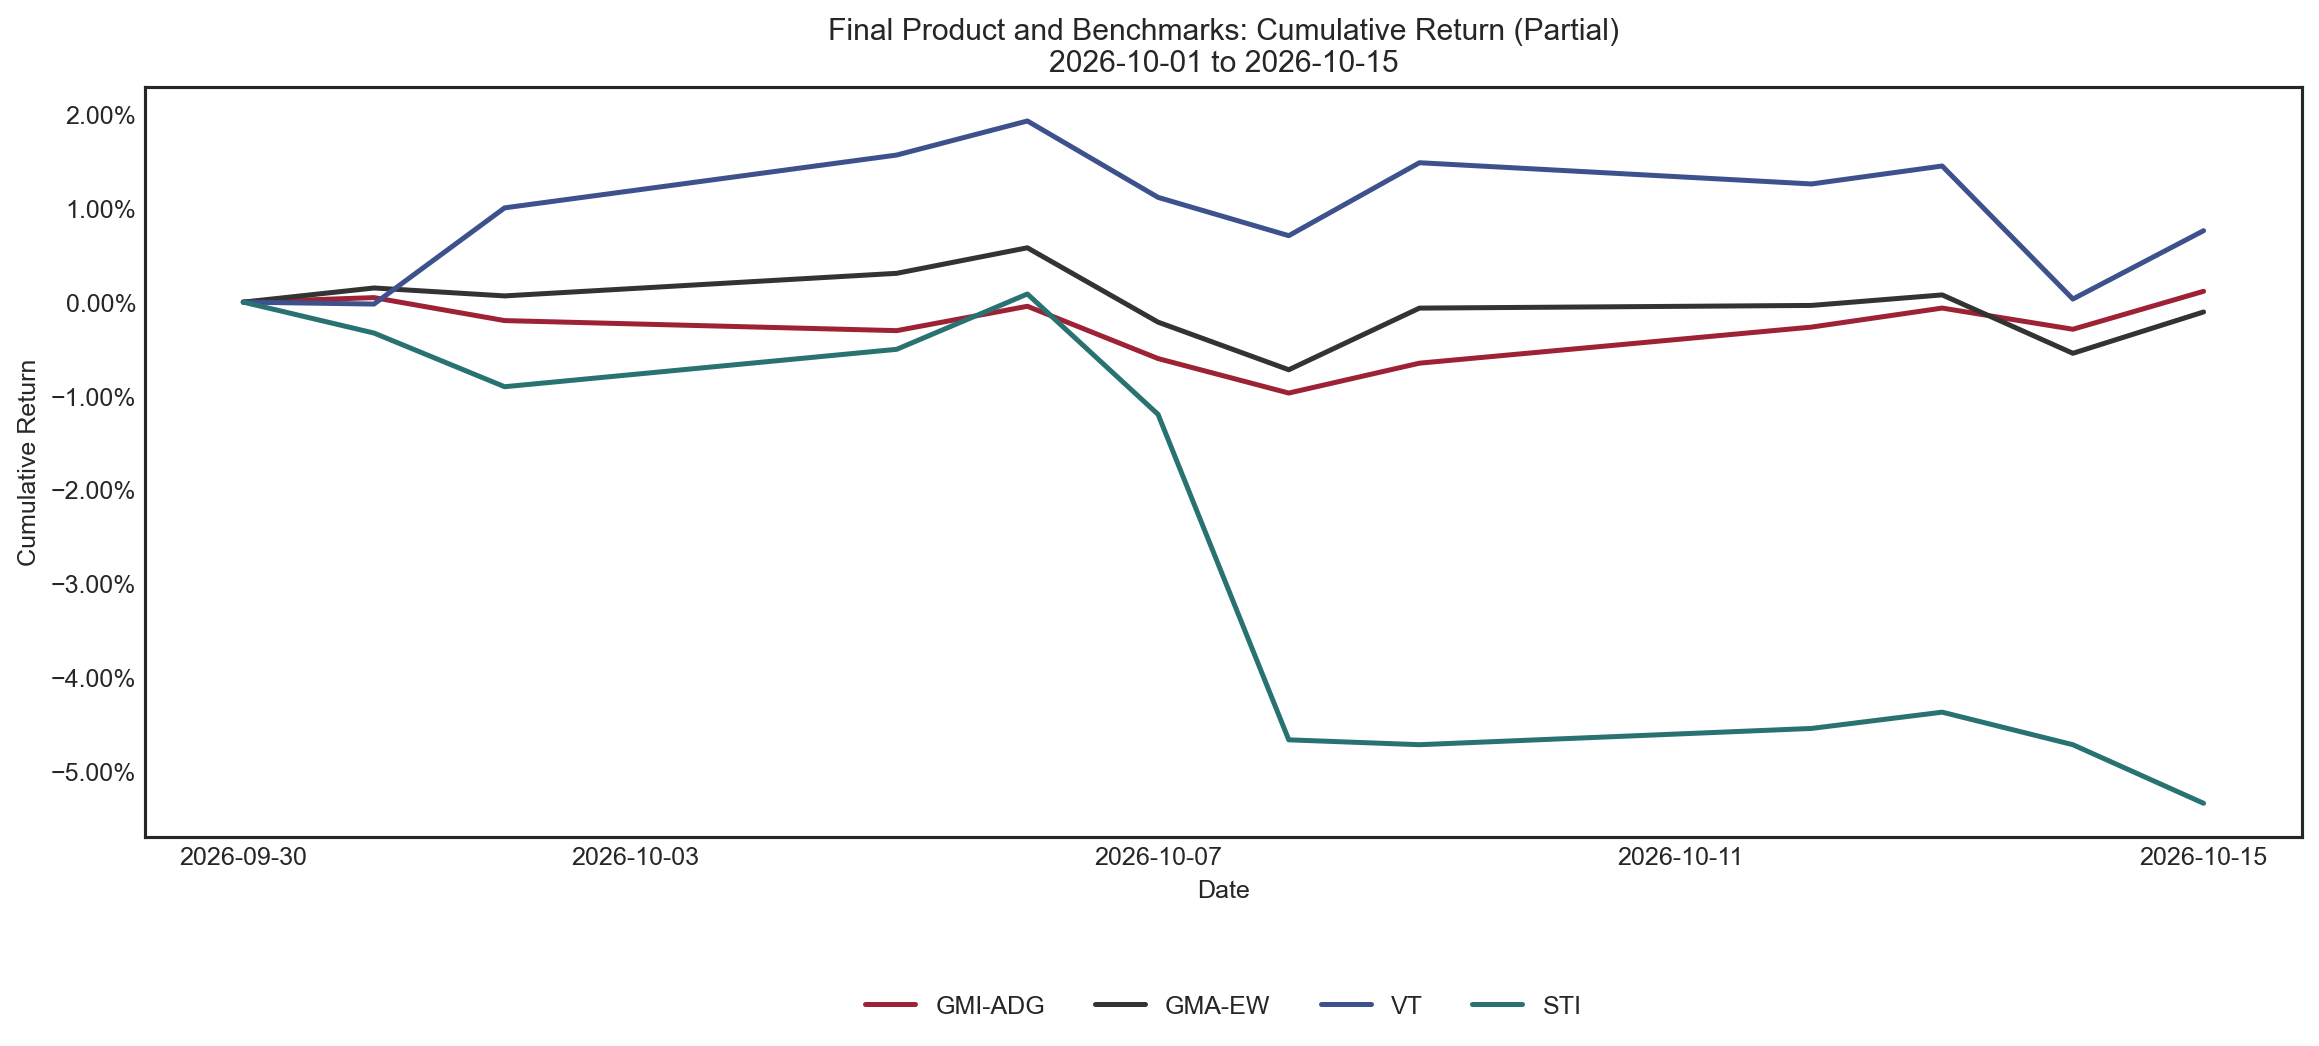

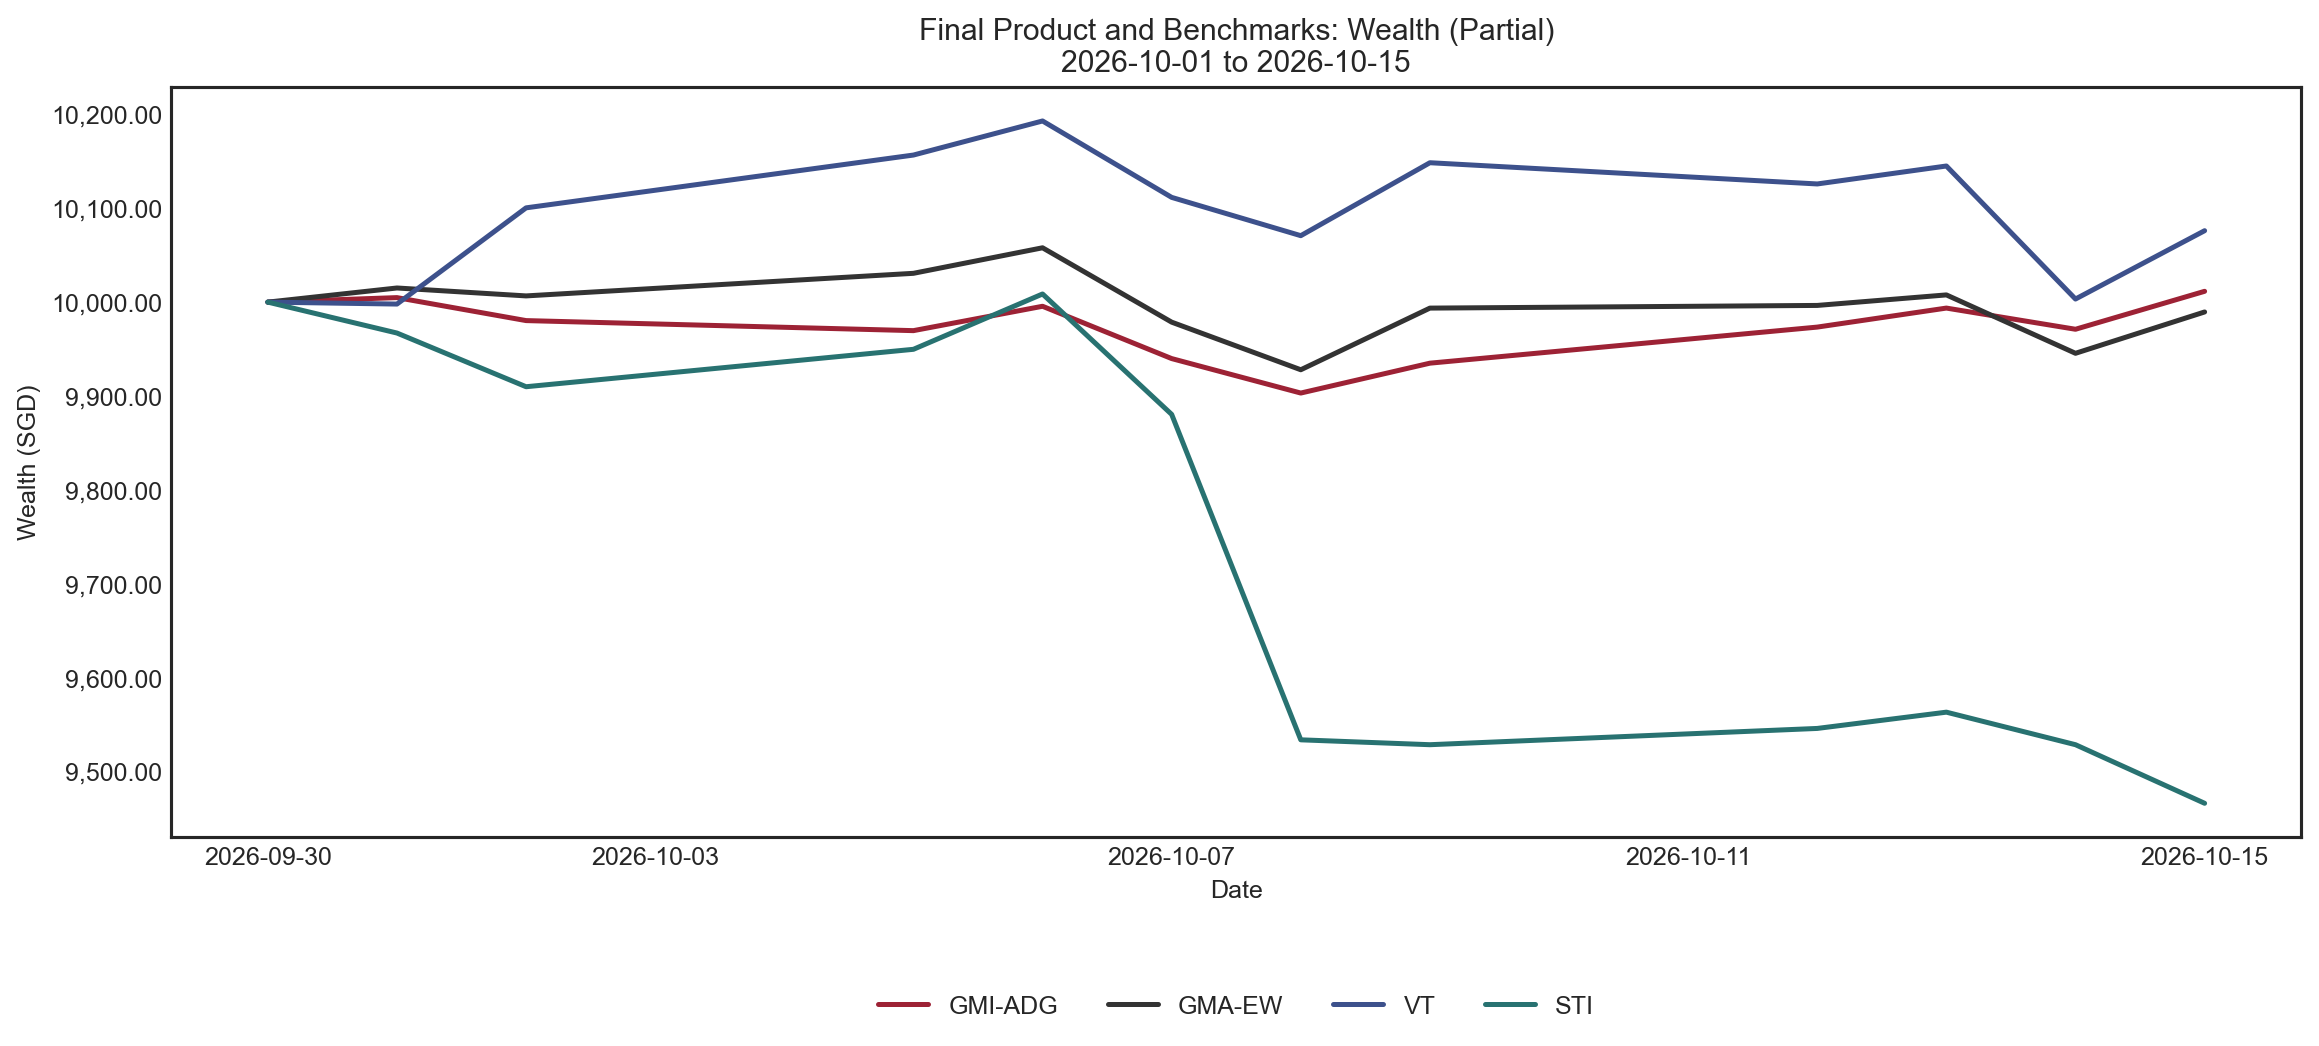

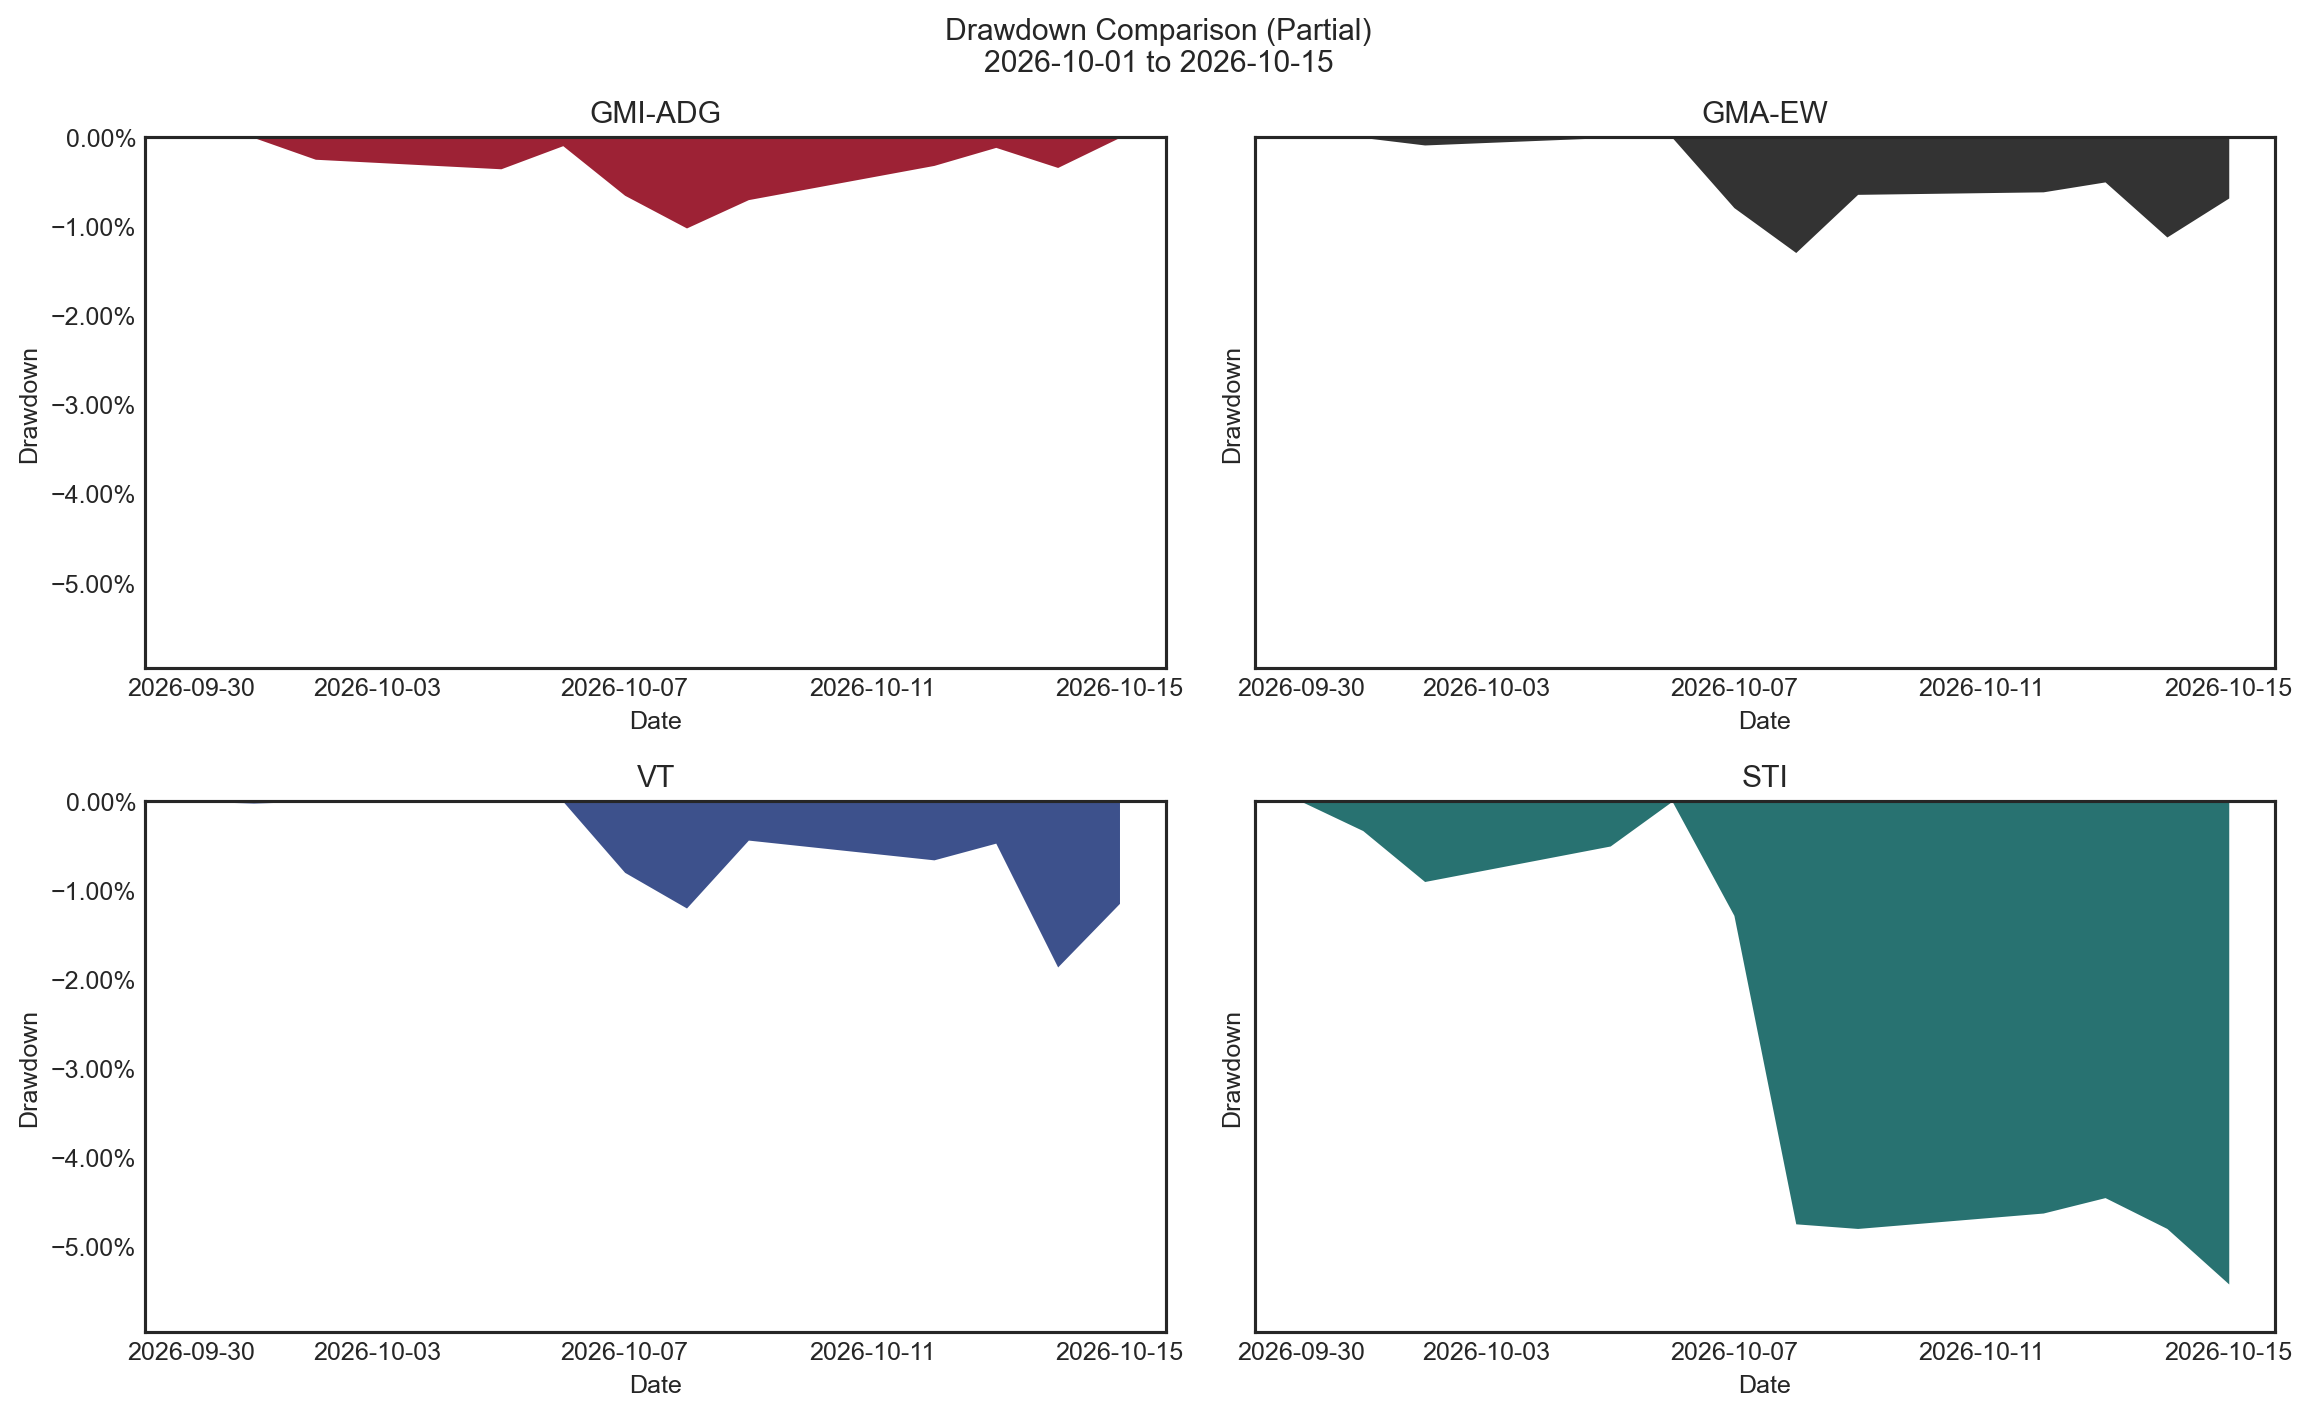

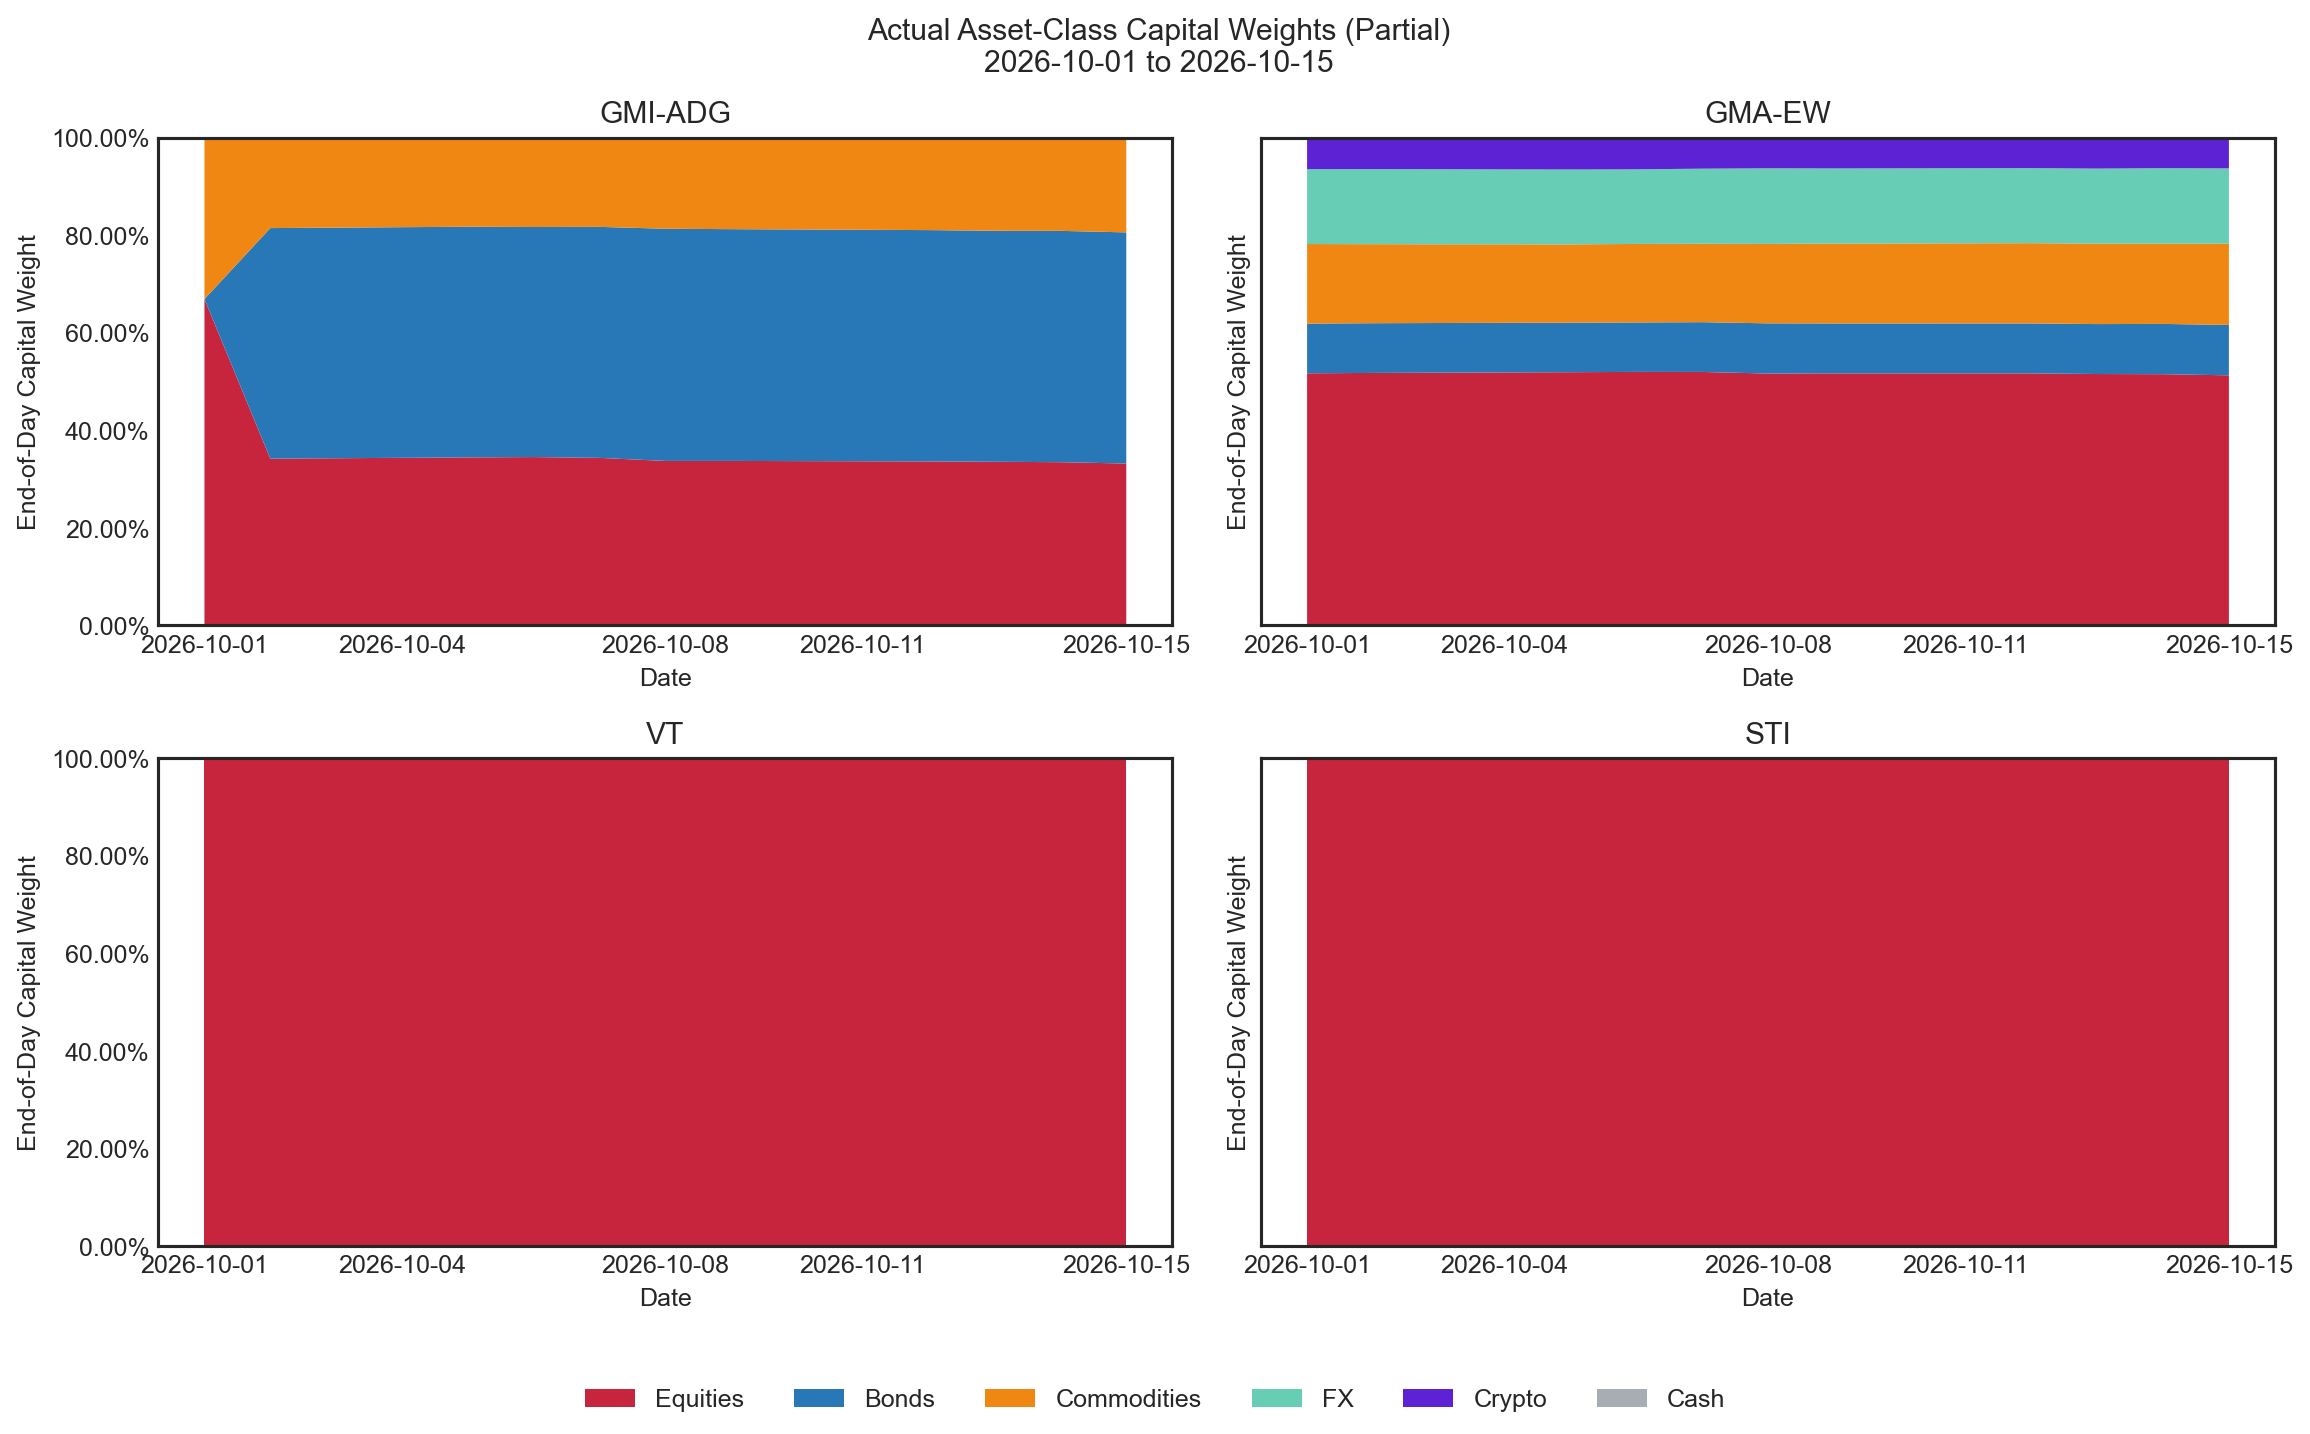

In [4]:
from IPython.display import Image, display
for image_path in report.get('charts', {}).values():
    display(Image(filename=image_path))
